# Identificación, estimación, simulación y pronóstico del Proceso de Reversión a la Media con ruido aditivo y tendencia funcional – Aplicación a la UVR

Este notebook es la traducción a Python del script MATLAB `IEPPRMRATFPEII20262.m` (y de las funciones auxiliares `fractalvol.m` y `genhurst.m`). Se conserva el mismo orden de pasos:

0. Carga y análisis inicial de la serie
1. Dimensión fractal y exponente de Hurst
2. Diferencias ponderadas (ρ del PACF) y pruebas de normalidad
3. Suavizado $m(t)$ y derivada $m_1(t)$
4. Perturbaciones aleatorias, pruebas ADF, ARCH y Ljung-Box
5. Volatilidad acumulada
6. Estimación de $\alpha$ y $\sigma$ (Parte I) y media de largo plazo $\hat\mu(t)$
7. Media funcional (**exponencial** como opción principal, polinomial como alternativa) y re-estimación (Parte II)
8. Pronósticos inducido y simulado, bandas de confianza del 95 %, cobertura y MAPE
9. Resumen final

Modelo: $dX_t = \big[\alpha(\mu(t) - X_t) + \mu'(t)\big]dt + \sigma X_t^{\gamma}\,dW_t$, con $\gamma = 0$ (ruido aditivo).

In [147]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from scipy import stats
from scipy.optimize import curve_fit
import statsmodels.api as sm
from statsmodels.tsa.stattools import pacf, adfuller
from statsmodels.graphics.tsaplots import plot_pacf
from statsmodels.graphics.gofplots import qqplot
from statsmodels.stats.diagnostic import normal_ad, lilliefors, het_arch, acorr_ljungbox

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (11, 4.5)
plt.rcParams["axes.titlesize"] = 13
pd.set_option("display.float_format", lambda v: f"{v:,.6f}")

# ----------------------------- PARÁMETROS CONFIGURABLES -----------------------------
archivo = "UVR_daily_2015_2025.csv"      # nombre del archivo CSV (columnas: fecha, valor)
dt = 1/365                     # frecuencia diaria. Puede cambiarse a 1/252 (días bursátiles) o 1/12 (mensual)
semilla = 12345                # semilla para reproducibilidad
k = 1000                       # número de trayectorias simuladas
n_plot = 150                   # trayectorias que se dibujan (solo afecta al gráfico, no a los cálculos)
ventana_mm = 300               # ventana del promedio móvil (movmean)
gamma = 0                      # 0 = ruido aditivo
MEDIA_FUNCIONAL = "exponencial"  # "exponencial" (principal)  |  "polinomial"
GRADO_POLY = 5                 # grado del polinomio (2 o 3) para la alternativa polinomial
AJUSTAR_SOBRE = "muest"        # "muest" = como en MATLAB (ajusta a mu_hat = m + m1/alpha)  |  "m" = ajusta a la media suavizada m(t)
CALCULAR_FRACTAL_HURST = True  # pone False para saltarse el Paso 1 si se quiere acelerar
rng = np.random.default_rng(semilla)

In [148]:
def fractalvol(data):
    """Dimensión fractal por conteo de cajas (traducción fiel de fractalvol.m).
    Embebe la serie en el cuadrado unitario y cuenta cajas de lado 2^-j.
    Devuelve (dimension, standard_dev)."""
    data = np.asarray(data, dtype=float)
    if data.ndim == 1:
        data = data.reshape(-1, 1)
    if data.shape[0] < data.shape[1]:
        data = data.T
    if data.shape[1] == 1:
        data = np.column_stack([np.arange(1, len(data) + 1), data[:, 0]])

    max1, min1 = data[:, 0].max(), data[:, 0].min()
    max2, min2 = data[:, 1].max(), data[:, 1].min()

    # normalizar al cuadrado unitario
    normdata = data.copy()
    normdata[:, 0] = (normdata[:, 0] - min1) / (max1 - min1)
    normdata[:, 1] = (normdata[:, 1] - min2) / (max2 - min2)

    # asegurar que nada se escape por el eje x
    minwidth = np.min(np.diff(normdata[:, 0]))
    minwidth = np.log2(minwidth)
    minwidth = int(abs(np.ceil(minwidth)))
    minwidth = minwidth - 1
    n = np.zeros(minwidth)

    xs, ys = normdata[:, 0], normdata[:, 1]
    for j in range(1, minwidth + 1):
        width = 2.0 ** (-j)
        xaxis_pos = 0.0
        boxcount = 0.0
        while xaxis_pos < 1:
            indx = (xaxis_pos <= xs) & (xs < xaxis_pos + width)
            if 1 - xaxis_pos == width:
                indx[-1] = True
            vertical_column = ys[indx]
            if len(vertical_column) == 1:
                boxcount += 1
            elif len(vertical_column) > 1:
                rawcount = (vertical_column.max() - vertical_column.min()) / width
                rawcount = rawcount + np.fmod(vertical_column.min(), width)   # rem de MATLAB
                boxcount += np.ceil(rawcount)
            xaxis_pos = xaxis_pos + width   # avanzar en el eje x
        n[j - 1] = boxcount

    r = 2.0 ** (-np.arange(1, minwidth + 1))
    s = -np.gradient(np.log(n)) / np.gradient(np.log(r))
    # iqr de MATLAB usa cuantiles con la convención (i-0.5)/n -> método 'hazen'
    IQR = np.percentile(s, 75, method="hazen") - np.percentile(s, 25, method="hazen")
    indx2 = np.abs(s - np.median(s)) > IQR / 2
    x2 = np.log(r)
    y2 = np.log(n)
    s = s[~indx2]
    x2 = x2[~indx2]
    y2 = y2[~indx2]

    # la desviación es la de la pendiente según teoría OLS
    X = np.column_stack([np.ones_like(x2), x2])
    beta = np.linalg.pinv(X) @ y2
    C = np.linalg.pinv(X.T @ X)
    e = y2 - X @ np.linalg.pinv(X) @ y2
    sigma = np.sqrt((e @ e) * C)
    dimension = -beta[1]
    standard_dev = sigma[1, 1]
    return dimension, standard_dev


def genhurst(S, q=1, maxT=19):
    """Exponente de Hurst generalizado H(q) (traducción fiel de genhurst.m, T. Aste 2013).
    Escala de los q-momentos renormalizados: <|x(t+r)-x(t)|^q>/<x(t)^q> ~ r^[qH(q)].
    Devuelve (mH, sH): H(q) medio y su desviación estándar, ambos arreglos de longitud len(q)."""
    S = np.asarray(S, dtype=float)
    if S.ndim == 2:
        if min(S.shape) == 1:
            S = S.ravel()
        else:
            print("S must be 1xT")
            return None, None
    q = np.atleast_1d(np.asarray(q, dtype=float))
    L = len(S)
    lq = len(q)
    if L < max(maxT * 4, 60):
        warnings.warn("Data serie very short!")

    H = []
    for Tmax in range(5, maxT + 1):
        x = np.arange(1, Tmax + 1)
        mcord = np.zeros((Tmax, lq))
        for tt in range(1, Tmax + 1):
            # índices de MATLAB (base 1) convertidos a base 0
            i1 = np.arange(tt + 1, L + 1, tt)
            dV = S[i1 - 1] - S[i1 - tt - 1]
            i2 = np.arange(tt + 1, L + tt + 1, tt) - tt
            VV = S[i2 - 1]
            N = len(dV) + 1
            X = np.arange(1, N + 1)
            Y = VV
            mx = X.sum() / N
            SSxx = (X ** 2).sum() - N * mx ** 2
            my = Y.sum() / N
            SSxy = (X * Y).sum() - N * mx * my
            cc1 = SSxy / SSxx
            cc2 = my - cc1 * mx
            ddVd = dV - cc1
            VVVd = VV - cc1 * X - cc2
            for qq in range(lq):
                mcord[tt - 1, qq] = np.mean(np.abs(ddVd) ** q[qq]) / np.mean(np.abs(VVVd) ** q[qq])
        lx = np.log10(x)
        mx = lx.mean()
        SSxx = (lx ** 2).sum() - Tmax * mx ** 2
        fila = np.zeros(lq)
        for qq in range(lq):
            lm = np.log10(mcord[:, qq])
            my = lm.mean()
            SSxy = (lx * lm).sum() - Tmax * mx * my
            fila[qq] = SSxy / SSxx
        H.append(fila)
    H = np.array(H)
    mH = H.mean(axis=0) / q
    sH = H.std(axis=0, ddof=1) / q
    return mH, sH


def movmean(x, w):
    """Equivalente a movmean(x, w) de MATLAB: ventana centrada que se encoge en los extremos.
    Para w par, la ventana incluye w/2 elementos previos y w/2-1 posteriores."""
    x = np.asarray(x, dtype=float)
    n = len(x)
    if w % 2 == 1:
        a, b = w // 2, w // 2
    else:
        a, b = w // 2, w // 2 - 1
    cs = np.concatenate([[0.0], np.cumsum(x)])
    idx = np.arange(n)
    lo = np.clip(idx - a, 0, n - 1)
    hi = np.clip(idx + b, 0, n - 1)
    return (cs[hi + 1] - cs[lo]) / (hi - lo + 1)


def mape(actual, forecast):
    """Error porcentual absoluto medio (en %), calculado a lo largo del último eje.
    Si forecast es una matriz (trayectorias x tiempo) devuelve un MAPE por trayectoria."""
    actual = np.asarray(actual, dtype=float)
    forecast = np.asarray(forecast, dtype=float)
    return np.mean(np.abs((actual - forecast) / actual), axis=-1) * 100


def fmt_test(nombre, stat, p, alpha=0.05):
    return {"Prueba": nombre, "Estadístico": stat, "Valor-p": p, "h (1 = rechaza H0)": int(p < alpha)}

## Carga de datos

El CSV debe tener dos columnas: fecha y valor (p. ej. `date,value` o `date,UVR`). Las fechas se usan **solo para graficar**; todos los cálculos estocásticos usan el arreglo `X`.

In [149]:
df = pd.read_csv(archivo)
df = df.iloc[:, :2].copy()
df.columns = ["date", "value"]
df["date"] = pd.to_datetime(df["date"])
df["value"] = pd.to_numeric(df["value"], errors="coerce")
df = df.dropna().sort_values("date").reset_index(drop=True)

dates = pd.DatetimeIndex(df["date"])
X = df["value"].to_numpy(dtype=float)
N = len(X)
print(f"Archivo: {archivo} | N = {N} observaciones | {dates[0].date()} -> {dates[-1].date()}")
df.head()

Archivo: UVR_daily_2015_2025.csv | N = 4018 observaciones | 2015-01-01 -> 2025-12-31


,date,value
0,2015-01-01,215.042400
1,2015-01-02,215.051400
2,2015-01-03,215.060400
3,2015-01-04,215.069400
4,2015-01-05,215.078400


## Análisis cuantitativo de la serie

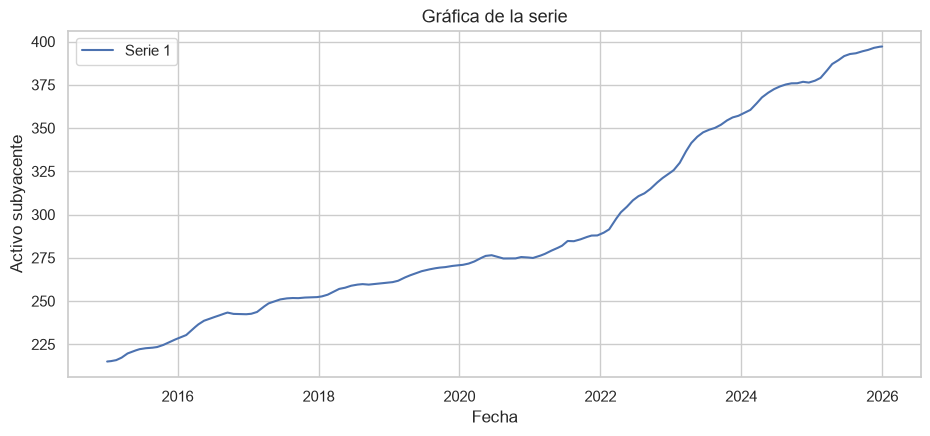

In [150]:
fig, ax = plt.subplots()
ax.plot(dates, X, label="Serie 1")
ax.set_xlabel("Fecha"); ax.set_ylabel("Activo subyacente")
ax.set_title("Gráfica de la serie"); ax.legend()
plt.show()

### Paso 0: Descripción estadística del activo

,mín,máx,media,mediana,moda,varianza,desv. est.,curtosis,asimetría
Serie X,215.042400,397.122700,291.240949,274.759600,274.590000,"2,820.622175",53.109530,2.109320,0.624286


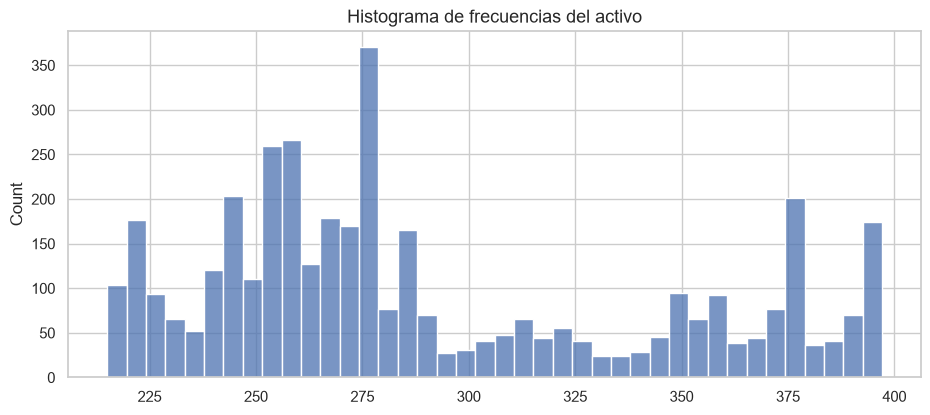

In [151]:
def descriptivos(v):
    return pd.Series({
        "mín": np.min(v), "máx": np.max(v), "media": np.mean(v), "mediana": np.median(v),
        "moda": stats.mode(v, keepdims=False).mode, "varianza": np.var(v, ddof=1),
        "desv. est.": np.std(v, ddof=1), "curtosis": stats.kurtosis(v, fisher=False),
        "asimetría": stats.skew(v),
    })

EstadX = descriptivos(X).to_frame("Serie X").T
display(EstadX)

fig, ax = plt.subplots()
sns.histplot(X, bins=40, ax=ax)
ax.set_title("Histograma de frecuencias del activo")
plt.show()

### Paso 1: Autocorrelación parcial, dimensión fractal y exponente de Hurst

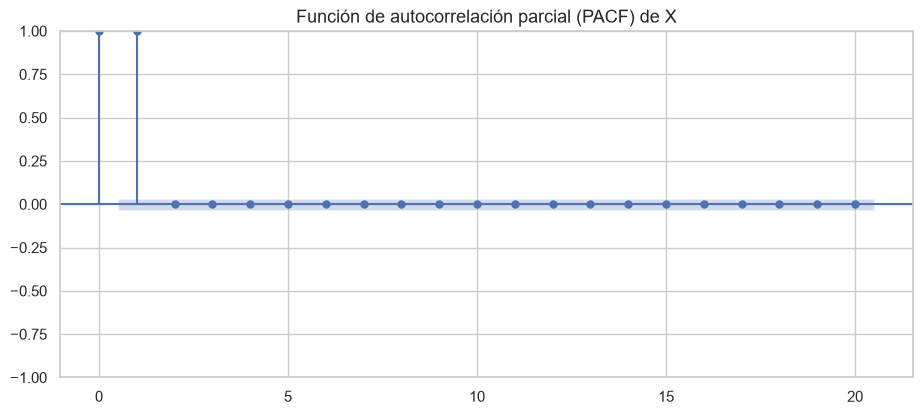

,Dimensión fractal (DF),Exponente de Hurst (EH),S = DF + EH
0,1.013648,0.995340,2.008989


In [152]:
fig, ax = plt.subplots()
plot_pacf(X, lags=20, method="ywm", ax=ax)
ax.set_title("Función de autocorrelación parcial (PACF) de X")
plt.show()

if CALCULAR_FRACTAL_HURST:
    DF, DF_sd = fractalvol(X)
    EH = genhurst(X)[0][0]
    resultado_fh = pd.DataFrame({"Dimensión fractal (DF)": [DF], "Exponente de Hurst (EH)": [EH], "S = DF + EH": [DF + EH]})
    display(resultado_fh)
else:
    DF = EH = np.nan

## Análisis de diferencias ponderadas

In [153]:
pacf_X = pacf(X, nlags=20, method="ywm")
rho = pacf_X[1]                      # PACF en el rezago 1
print(f"rho (PACF rezago 1) = {rho:.8f}")

DP = X[1:] - rho * X[:-1]            # diferencias ponderadas

EstadD = descriptivos(DP).to_frame("DP").T
display(EstadD)

rho (PACF rezago 1) = 0.99924837


,mín,máx,media,mediana,moda,varianza,desv. est.,curtosis,asimetría
DP,0.156351,0.463466,0.264213,0.246360,0.206390,0.004394,0.066284,2.667888,0.703773


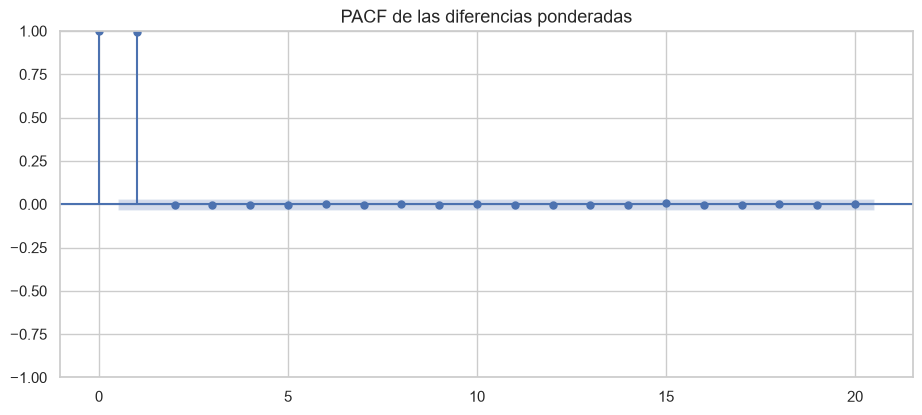

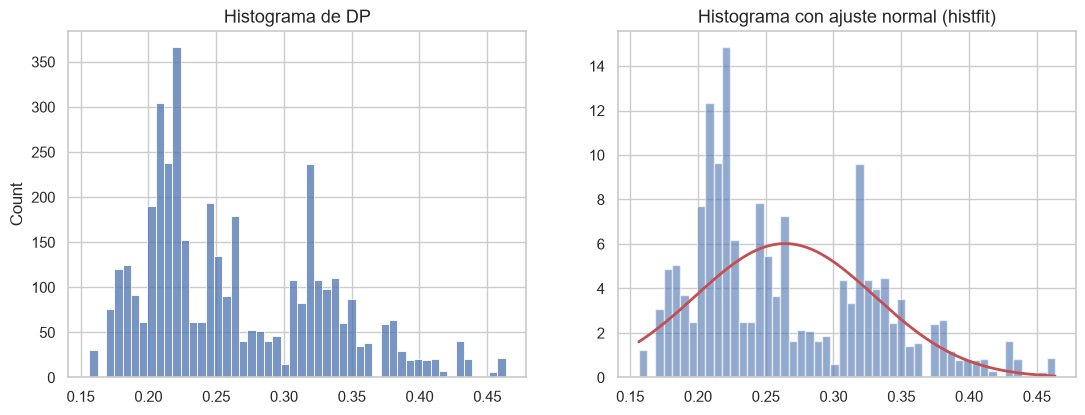

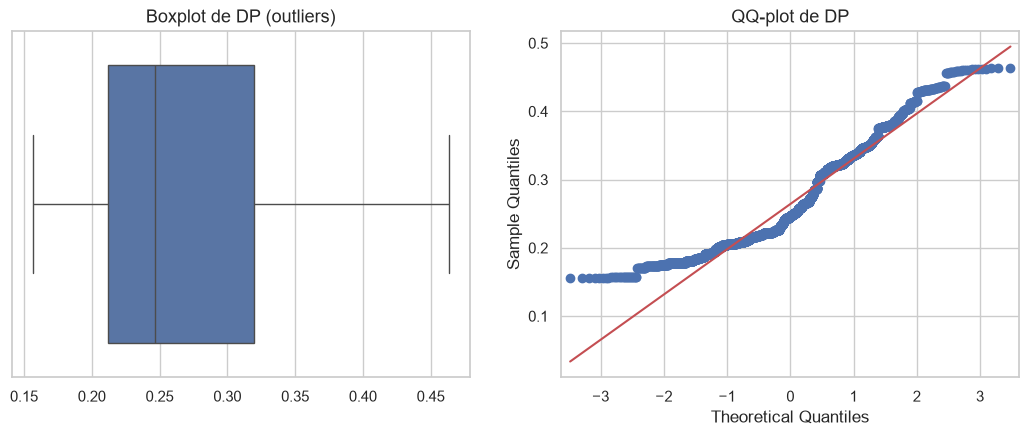

In [154]:
# PACF de DP
fig, ax = plt.subplots()
plot_pacf(DP, lags=20, method="ywm", ax=ax)
ax.set_title("PACF de las diferencias ponderadas")
plt.show()

# Histograma y histograma con ajuste normal (histfit)
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(DP, bins=50, ax=axs[0]); axs[0].set_title("Histograma de DP")
axs[1].hist(DP, bins=50, density=True, alpha=0.6)
xx = np.linspace(DP.min(), DP.max(), 400)
axs[1].plot(xx, stats.norm.pdf(xx, DP.mean(), DP.std(ddof=1)), "r", lw=2)
axs[1].set_title("Histograma con ajuste normal (histfit)")
plt.show()

# Boxplot y QQ-plot (outliers)
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(x=DP, ax=axs[0]); axs[0].set_title("Boxplot de DP (outliers)")
qqplot(DP, line="s", ax=axs[1]); axs[1].set_title("QQ-plot de DP")
plt.show()
# DP = np.delete(DP, indices)   # remoción de outliers (opcional)

### Paso 3: Pruebas de normalidad de las diferencias ponderadas

In [155]:
m_dp = DP.mean()
des = DP.std(ddof=1)
Zs = (DP - m_dp) / des

jb = stats.jarque_bera(DP)
ks = stats.kstest(Zs, "norm")
ad_stat, ad_p = normal_ad(DP)
li_stat, li_p = lilliefors(DP, dist="norm")

PNorRet = pd.DataFrame([
    fmt_test("Jarque-Bera (jbtest)", jb.statistic, jb.pvalue),
    fmt_test("Kolmogórov-Smirnov (kstest)", ks.statistic, ks.pvalue),
    fmt_test("Anderson-Darling (adtest)", ad_stat, ad_p),
    fmt_test("Lilliefors (lillietest)", li_stat, li_p),
])
display(PNorRet)

,Prueba,Estadístico,Valor-p,h (1 = rechaza H0)
0,Jarque-Bera (jbtest),350.062093,0.000000,1
1,Kolmogórov-Smirnov (kstest),0.143087,0.000000,1
2,Anderson-Darling (adtest),97.832644,0.000000,1
3,Lilliefors (lillietest),0.143087,0.001000,1


## Suavizado de la serie y estimación de $m_1(t)$ (Estimación Parte I)

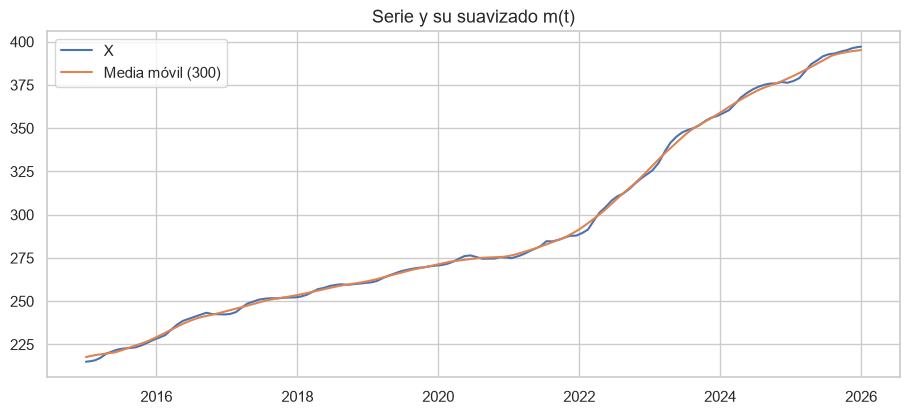

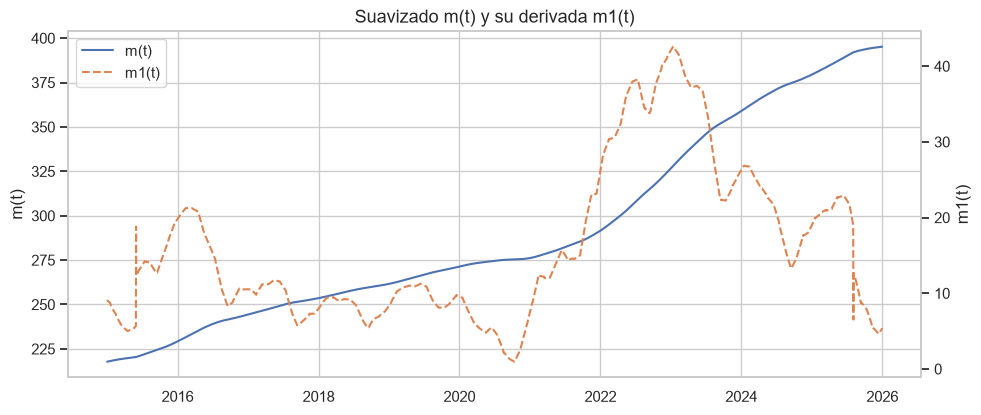

In [156]:
m = movmean(X, ventana_mm)

fig, ax = plt.subplots()
ax.plot(dates, X, label="X"); ax.plot(dates, m, label=f"Media móvil ({ventana_mm})")
ax.set_title("Serie y su suavizado m(t)"); ax.legend()
plt.show()

# Derivada de m(t) (misma fórmula del script MATLAB)
m1 = np.zeros(N)
m1[0] = (m[1] - m[0]) / dt
m1[1:N-1] = (2 * m[2:N] - 3 * m[1:N-1] + m[0:N-2]) / dt
m1[N-1] = (m[N-1] - m[N-2]) / dt

fig, ax = plt.subplots()
ax.plot(dates, m, label="m(t)")
ax.set_ylabel("m(t)")
ax2 = ax.twinx()
ax2.plot(dates, m1, "--", color="C1", label="m1(t)")
ax2.set_ylabel("m1(t)"); ax2.grid(False)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left")
ax.set_title("Suavizado m(t) y su derivada m1(t)")
plt.show()

## Paso 4: Análisis de heterocedasticidad de las perturbaciones aleatorias

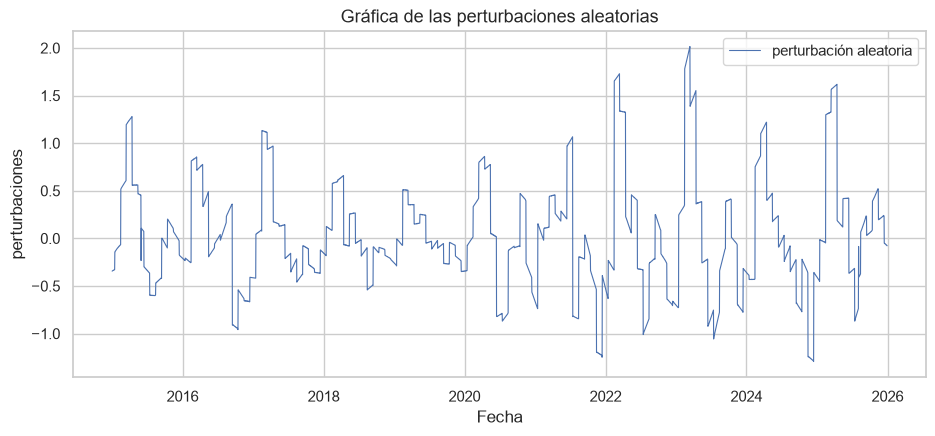

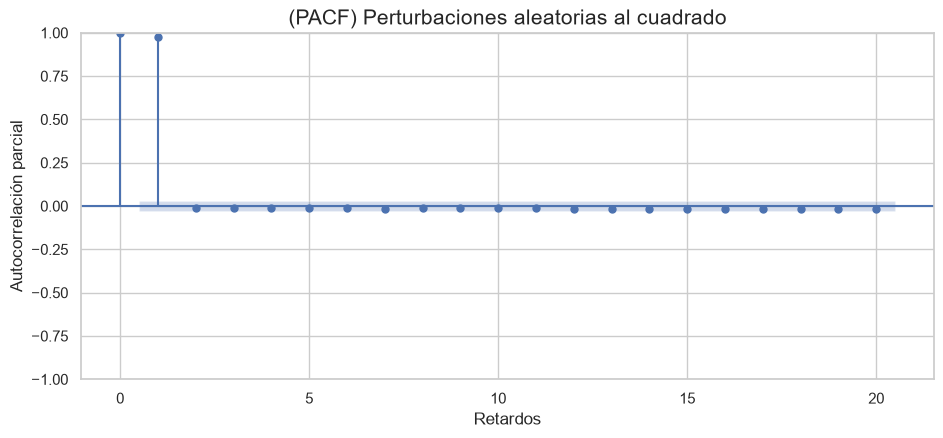

In [157]:
PA = (X[1:] - (1 - rho) * m[:-1] - m1[:-1] * dt - rho * X[:-1]) / np.sqrt(dt)   # perturbación aleatoria
PA2 = PA ** 2

fig, ax = plt.subplots()
ax.plot(dates[:-1], PA, label="perturbación aleatoria", lw=0.8)
ax.set_xlabel("Fecha"); ax.set_ylabel("perturbaciones")
ax.set_title("Gráfica de las perturbaciones aleatorias"); ax.legend()
plt.show()

fig, ax = plt.subplots()
plot_pacf(PA2, lags=20, method="ywm", ax=ax)
ax.set_title("(PACF) Perturbaciones aleatorias al cuadrado", fontsize=15)
ax.set_xlabel("Retardos"); ax.set_ylabel("Autocorrelación parcial")
plt.show()

### Pruebas ADF, ARCH (Engle) y Ljung-Box

In [158]:
# ---- Test ADF (equivalente a adftest(PA) de MATLAB: modelo AR sin constante, 0 rezagos).
# Alternativa más habitual en Python: regression="c", autolag="AIC".
res_adf = adfuller(PA, maxlag=0, regression="n", autolag=None)
adf_stat, adf_p, adf_crit = res_adf[0], res_adf[1], res_adf[4]
h_adf = int(adf_p < 0.05)
TADF = pd.DataFrame({"h": [h_adf], "Valor Crítico (5%)": [adf_crit["5%"]],
                     "Estadístico": [adf_stat], "Valor-p": [adf_p]})
display(TADF)
print("\n--- Test ADF sobre perturbaciones aleatorias ---")
print(f"Estadístico ADF: {adf_stat:.4f} | Valor crítico al 5%: {adf_crit['5%']:.4f} | Valor-p: {adf_p:.4f}")
if h_adf == 1:
    print("Resultado: Se rechaza H0. Las perturbaciones son estacionarias - la serie revierte a la tendencia funcional.")
else:
    print("Resultado: No se rechaza H0. Las perturbaciones no son estacionarias - la serie NO revierte a la tendencia.")

# ---- Test ARCH de Engle
q_arch = 5
lm_arch, p_arch, _, _ = het_arch(PA, nlags=q_arch)
crit_arch = stats.chi2.ppf(0.95, q_arch)
h_arch = int(p_arch < 0.05)
TE = pd.DataFrame({"h": [h_arch], "Valor Crítico (5%)": [crit_arch], "Estadístico": [lm_arch], "Valor-p": [p_arch]})
print("\n--- Test ARCH (Engle) ---")
display(TE)
if h_arch == 1:
    print("Resultado: Se rechaza H0 - hay evidencia de heterocedasticidad condicional (efecto ARCH).")
else:
    print("Resultado: No se rechaza H0 - no se detecta heterocedasticidad condicional (no hay efecto ARCH).")

# ---- Test de Ljung-Box sobre PA^2
q_lbq = 5
lb = acorr_ljungbox(PA2, lags=[q_lbq])
stat_lbq = float(lb["lb_stat"].iloc[0]); p_lbq = float(lb["lb_pvalue"].iloc[0])
crit_lbq = stats.chi2.ppf(0.95, q_lbq)
h_lbq = int(p_lbq < 0.05)
TLB = pd.DataFrame({"h": [h_lbq], "Valor Crítico (5%)": [crit_lbq], "Estadístico": [stat_lbq], "Valor-p": [p_lbq]})
print("\n--- Test Ljung-Box sobre PA^2 ---")
display(TLB)
if h_lbq == 1:
    print("Resultado: Se rechaza H0 - hay autocorrelación en la varianza, posible efecto GARCH.")
else:
    print("Resultado: No se rechaza H0 - no se detecta autocorrelación en la varianza.")

,h,Valor Crítico (5%),Estadístico,Valor-p
0,1,-1.941067,-5.884274,0.000000



--- Test ADF sobre perturbaciones aleatorias ---
Estadístico ADF: -5.8843 | Valor crítico al 5%: -1.9411 | Valor-p: 0.0000
Resultado: Se rechaza H0. Las perturbaciones son estacionarias - la serie revierte a la tendencia funcional.

--- Test ARCH (Engle) ---


,h,Valor Crítico (5%),Estadístico,Valor-p
0,1,11.070498,"3,816.152648",0.000000


Resultado: Se rechaza H0 - hay evidencia de heterocedasticidad condicional (efecto ARCH).

--- Test Ljung-Box sobre PA^2 ---


,h,Valor Crítico (5%),Estadístico,Valor-p
0,1,11.070498,"17,261.482598",0.000000


Resultado: Se rechaza H0 - hay autocorrelación en la varianza, posible efecto GARCH.


## Paso 5: Prueba gráfica empírica de volatilidad constante

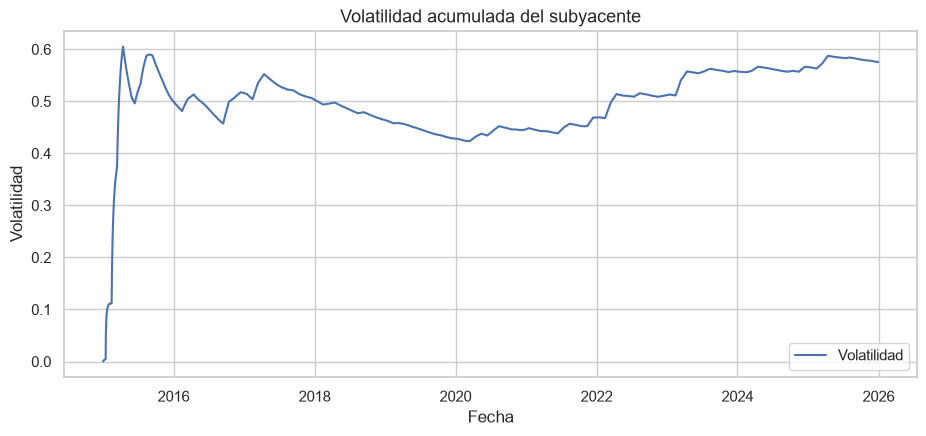

Valor estimado tentativo de la volatilidad constante: 0.575323


In [159]:
# Volatilidad dinámica: desviación estándar acumulada de PA (ddof=1 como en MATLAB)
nn = np.arange(1, N)                      # tamaños de muestra 1..N-1
cs, cs2 = np.cumsum(PA), np.cumsum(PA2)
VE = np.zeros(N - 1)
VE[1:] = np.sqrt(np.maximum((cs2[1:] - cs[1:] ** 2 / nn[1:]) / (nn[1:] - 1), 0))

fig, ax = plt.subplots()
ax.plot(dates[:-1], VE, label="Volatilidad")
ax.set_xlabel("Fecha"); ax.set_ylabel("Volatilidad")
ax.set_title("Volatilidad acumulada del subyacente"); ax.legend()
plt.show()

vol = VE[-1]
print(f"Valor estimado tentativo de la volatilidad constante: {vol:.6f}")

## Paso 6: Estimación de parámetros (Parte I, con $m(t)$ suavizada)

,alpha,sigma
0,0.163586,0.575564


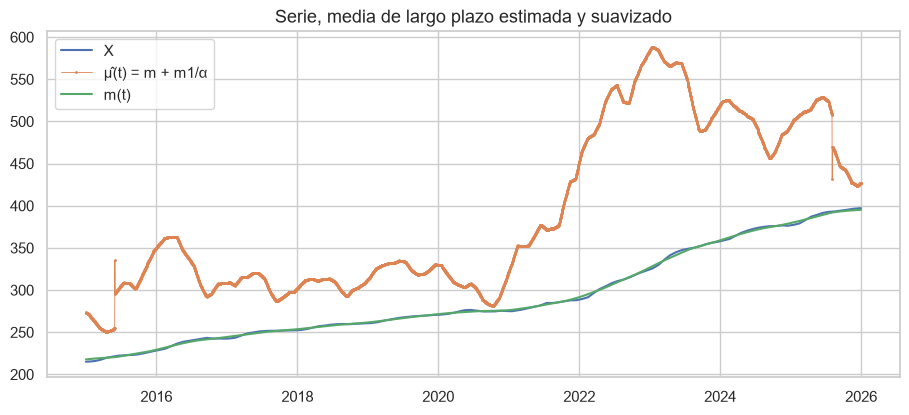

In [160]:
# Arreglos desplazados: índice j -> (X[j], X[j-1]) para j = 1..N-1
Xp, Xc = X[:-1], X[1:]
A = (Xc - Xp - m1[:-1] * dt) * (m[:-1] - Xp) / Xp ** (2 * gamma)      # Ecuación (16)
B = ((m[:-1] - Xp) / Xp ** gamma) ** 2 * dt
alphaest = A.sum() / B.sum()

C = ((Xc - Xp - (alphaest * (m[:-1] - Xp) + m1[:-1]) * dt) / Xp ** gamma) ** 2
sigmaest = np.sqrt(1 / (N * dt) * C.sum())

muest = m + m1 / alphaest       # media de largo plazo estimada

Est1 = pd.DataFrame({"alpha": [alphaest], "sigma": [sigmaest]})
display(Est1)
if alphaest <= 0:
    print("ADVERTENCIA: alpha estimado <= 0. No hay evidencia de reversión a la media en m(t); "
          "mu_hat = m + m1/alpha queda distorsionada (m1/alpha cambia de signo y escala). "
          "Considere AJUSTAR_SOBRE = \"m\" en la celda de parámetros.")

fig, ax = plt.subplots()
ax.plot(dates, X, label="X")
ax.plot(dates, muest, ".-", ms=2, lw=0.6, label="μ̂(t) = m + m1/α")
ax.plot(dates, m, label="m(t)")
ax.set_title("Serie, media de largo plazo estimada y suavizado"); ax.legend()
plt.show()

## Estimación Parte II: ajuste de la media funcional

Se ajusta una función paramétrica $\mu(t)$ a la media de largo plazo estimada $\hat\mu(t)$, con $t = 0, dt, 2dt, \dots$ (en años):

- **Opción principal – exponencial:** $\mu(t) = a\,e^{b t} + c$ (`scipy.optimize.curve_fit`).
- **Alternativa – polinomial:** grado 2 o 3 (`np.polyfit`), equivalente a `polyfit` de MATLAB.

Se ajustan ambas y se compara su error; la variable `MEDIA_FUNCIONAL` decide cuál se usa en la re-estimación y los pronósticos.

,Modelo,RMSE vs serie ajustada,R²
0,Exponencial a·exp(b·t)+c,56.291472,0.673705
1,Polinomial grado 5,32.937846,0.888284


Parámetros exponenciales: a = 225.930357, b = 0.073546, c = 41.781537
Coeficientes polinomiales (mayor grado primero): [ 5.84830000e-02 -2.06364700e+00  2.45627230e+01 -1.14781108e+02
  1.98751794e+02  2.25849902e+02]

>>> Media funcional utilizada: exponencial


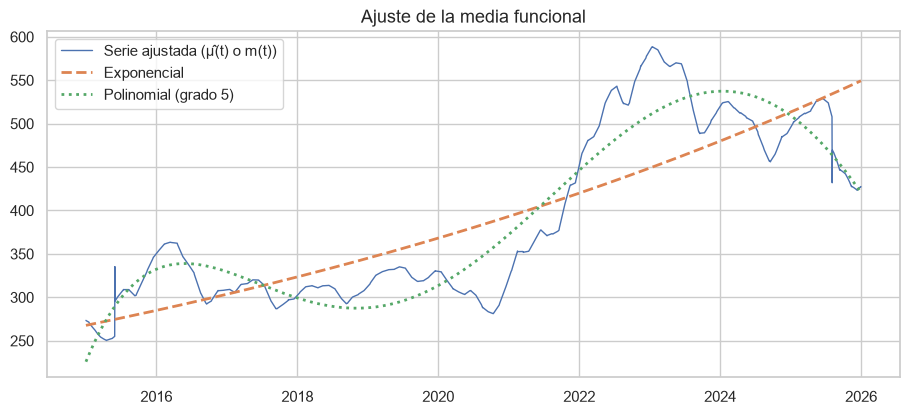

In [161]:
t = np.arange(N) * dt

# ---------- Media exponencial: mu(t) = a*exp(b*t) + c ----------
def mu_exp(t, a, b, c):
    return a * np.exp(b * t) + c

# valores iniciales robustos: regresión lineal de log(mu) sobre t (c0 = 0)
y_ajuste = muest if AJUSTAR_SOBRE == "muest" else m   # serie sobre la que se ajusta la media funcional
base = y_ajuste[y_ajuste > 0]
b0, la0 = np.polyfit(t[y_ajuste > 0], np.log(base), 1)
p0 = [np.exp(la0), b0, 0.0]
try:
    popt_exp, pcov_exp = curve_fit(mu_exp, t, y_ajuste, p0=p0, maxfev=200000)
except RuntimeError:
    popt_exp, pcov_exp = curve_fit(mu_exp, t, y_ajuste, p0=[y_ajuste[-1] - y_ajuste[0], 0.05, y_ajuste[0]], maxfev=200000)
a_est, b_est, c_est = popt_exp
mu_exp_vals = mu_exp(t, *popt_exp)

# ---------- Media polinomial ----------
p_poly = np.polyfit(t, y_ajuste, GRADO_POLY)
mu_poly_vals = np.polyval(p_poly, t)

rmse = lambda y: np.sqrt(np.mean((y_ajuste - y) ** 2))
r2 = lambda y: 1 - np.sum((y_ajuste - y) ** 2) / np.sum((y_ajuste - y_ajuste.mean()) ** 2)
comp = pd.DataFrame({
    "Modelo": [f"Exponencial a·exp(b·t)+c", f"Polinomial grado {GRADO_POLY}"],
    "RMSE vs serie ajustada": [rmse(mu_exp_vals), rmse(mu_poly_vals)],
    "R²": [r2(mu_exp_vals), r2(mu_poly_vals)],
})
display(comp)
print(f"Parámetros exponenciales: a = {a_est:.6f}, b = {b_est:.6f}, c = {c_est:.6f}")
print("Coeficientes polinomiales (mayor grado primero):", np.round(p_poly, 6))

# ---------- Selección de la media funcional ----------
if MEDIA_FUNCIONAL == "exponencial":
    murest = mu_exp_vals
    etiqueta_media = "exponencial"
elif MEDIA_FUNCIONAL == "polinomial":
    murest = mu_poly_vals
    etiqueta_media = f"polinomial grado {GRADO_POLY}"
else:
    raise ValueError("MEDIA_FUNCIONAL debe ser 'exponencial' o 'polinomial'")
print(f"\n>>> Media funcional utilizada: {etiqueta_media}")

fig, ax = plt.subplots()
ax.plot(dates, y_ajuste, lw=1, label="Serie ajustada (μ̂(t) o m(t))")
ax.plot(dates, mu_exp_vals, "--", lw=2, label="Exponencial")
ax.plot(dates, mu_poly_vals, ":", lw=2, label=f"Polinomial (grado {GRADO_POLY})")
ax.set_title("Ajuste de la media funcional"); ax.legend()
plt.show()

### Re-estimación de $\alpha$ y $\sigma$ con la media funcional

In [162]:
Ar = (Xc - Xp) * (murest[:-1] - Xp) / Xp ** (2 * gamma)
Br = ((murest[:-1] - Xp) / Xp ** gamma) ** 2 * dt
alpharest = Ar.sum() / Br.sum()

Cr = ((Xc - Xp - alpharest * (murest[:-1] - Xp) * dt) / Xp ** gamma) ** 2
sigmarest = np.sqrt(1 / (N * dt) * Cr.sum())

Est2 = pd.DataFrame({"alpha": [alpharest], "sigma": [sigmarest]}, index=[f"Media {etiqueta_media}"])
display(Est2)

,alpha,sigma
Media exponencial,0.166087,0.774696


## Paso 7: Pronósticos

### a) Pronóstico inducido (cada paso parte del valor real anterior)

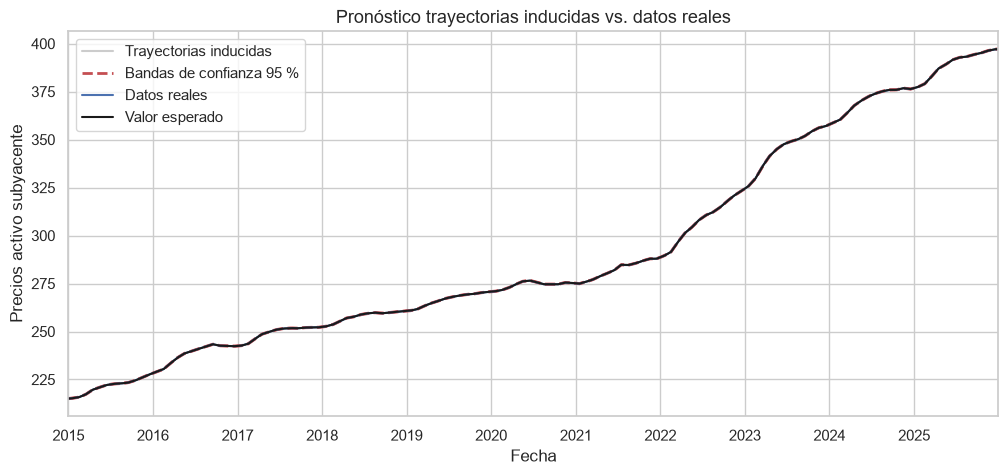

Cobertura de las bandas del 95 % (inducido): 0.9567


,mín,media,máx
MAPE trayectorias (%),0.015255,0.015760,0.016284


MAPE del valor esperado (inducido): 0.0106 %


In [163]:
def graficar_trayectorias(dates, T, banda, X, esperado, titulo, etiqueta, n_plot, rng):
    idx = rng.choice(T.shape[0], size=min(n_plot, T.shape[0]), replace=False)
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(dates, T[idx].T, color="0.8", lw=0.5)
    h1 = ax.plot([], [], color="0.8", label=etiqueta)[0]
    h2 = ax.plot(dates, banda[0], "r--", lw=2, label="Bandas de confianza 95 %")[0]
    ax.plot(dates, banda[1], "r--", lw=2)
    h3 = ax.plot(dates, X, "b", lw=1.5, label="Datos reales")[0]
    h4 = ax.plot(dates, esperado, "k", lw=1.5, label="Valor esperado")[0]
    ax.set_xlim(dates[0], dates[-1])
    ax.set_title(titulo); ax.set_ylabel("Precios activo subyacente"); ax.set_xlabel("Fecha")
    ax.legend(handles=[h1, h2, h3, h4])
    plt.show()

# XI[i, 0] = X[0];  XI[i, j] = X[j-1] + alpha*(mu[j-1]-X[j-1])*dt + sigma*sqrt(dt)*Z
XI = np.empty((k, N))
XI[:, 0] = X[0]
XI[:, 1:] = (X[:-1] + alpharest * (murest[:-1] - X[:-1]) * dt
             + sigmarest * np.sqrt(dt) * rng.standard_normal((k, N - 1)))

VECXI = XI.mean(axis=0)
CXICI = np.quantile(XI, [0.025, 0.975], axis=0)

graficar_trayectorias(dates, XI, CXICI, X, VECXI,
                      "Pronóstico trayectorias inducidas vs. datos reales",
                      "Trayectorias inducidas", n_plot, rng)

PXI = (CXICI[0] <= X) & (X <= CXICI[1])
PBBXI = PXI.mean()
maXI = mape(X, XI)
rmaXI = pd.DataFrame({"mín": [maXI.min()], "media": [maXI.mean()], "máx": [maXI.max()]}, index=["MAPE trayectorias (%)"])
mape_esp_XI = mape(X, VECXI)

print(f"Cobertura de las bandas del 95 % (inducido): {PBBXI:.4f}")
display(rmaXI)
print(f"MAPE del valor esperado (inducido): {mape_esp_XI:.4f} %")

### b) Pronóstico simulado (trayectorias independientes desde $X_0$)

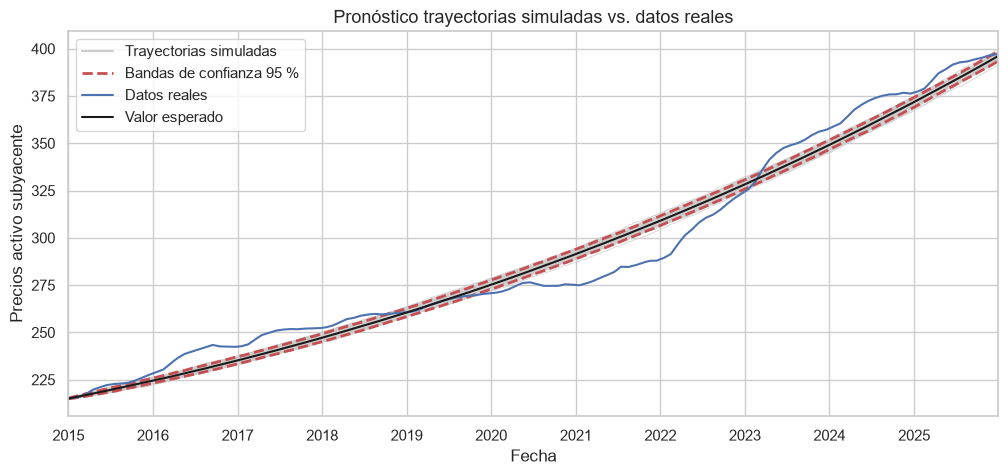

Cobertura de las bandas del 95 % (simulado): 0.1282


,mín,media,máx
MAPE trayectorias (%),2.396605,2.697148,3.070694


MAPE del valor esperado (simulado): 2.6771 %


In [164]:
XS = np.empty((k, N))
XS[:, 0] = X[0]
Z = rng.standard_normal((k, N - 1))
for j in range(1, N):
    XS[:, j] = (XS[:, j - 1] + alpharest * (murest[j - 1] - XS[:, j - 1]) * dt
                + sigmarest * np.sqrt(dt) * Z[:, j - 1])

VECXS = XS.mean(axis=0)
CXSCI = np.quantile(XS, [0.025, 0.975], axis=0)

graficar_trayectorias(dates, XS, CXSCI, X, VECXS,
                      "Pronóstico trayectorias simuladas vs. datos reales",
                      "Trayectorias simuladas", n_plot, rng)

PXS = (CXSCI[0] <= X) & (X <= CXSCI[1])
PBBXS = PXS.mean()
maXS = mape(X, XS)
rmaXS = pd.DataFrame({"mín": [maXS.min()], "media": [maXS.mean()], "máx": [maXS.max()]}, index=["MAPE trayectorias (%)"])
mape_esp_XS = mape(X, VECXS)

print(f"Cobertura de las bandas del 95 % (simulado): {PBBXS:.4f}")
display(rmaXS)
print(f"MAPE del valor esperado (simulado): {mape_esp_XS:.4f} %")

## Paso 8: Análisis del error (opcional)

En el script original esta sección está comentada. Aquí se calculan las medidas de error del valor esperado de cada pronóstico frente a los datos reales.

In [165]:
def medidas_error(real, pron):
    e = real - pron
    return {"SE": e.sum(), "SAE": np.abs(e).sum(), "EAM": np.abs(e).mean(),
            "MSE": (e ** 2).mean(), "RMSE": np.sqrt((e ** 2).mean()),
            "R (correlación)": np.corrcoef(real, pron)[0, 1] if np.std(pron) > 0 else np.nan}

errores = pd.DataFrame({"Inducido (valor esperado)": medidas_error(X, VECXI),
                        "Simulado (valor esperado)": medidas_error(X, VECXS)})
display(errores)

,Inducido (valor esperado),Simulado (valor esperado)
SE,2.086302,"2,667.323614"
SAE,124.426697,"31,195.099054"
EAM,0.030967,7.763837
MSE,0.001646,86.683297
RMSE,0.040575,9.310386
R (correlación),1.000000,0.984590


## Resumen final

In [166]:
resumen_param = pd.DataFrame({
    "Parámetro": ["rho (PACF lag 1)", "alpha (Parte I, m suavizada)", "sigma (Parte I)",
                  f"alpha (media {etiqueta_media})", f"sigma (media {etiqueta_media})",
                  "a (exponencial)", "b (exponencial)", "c (exponencial)",
                  "Volatilidad acumulada final", "Dimensión fractal", "Exponente de Hurst"],
    "Valor": [rho, alphaest, sigmaest, alpharest, sigmarest, a_est, b_est, c_est, vol, DF, EH],
})
display(resumen_param)

resumen_met = pd.DataFrame({
    "Métrica": ["Cobertura bandas 95 %", "MAPE valor esperado (%)", "MAPE medio trayectorias (%)",
                "RMSE media funcional vs serie ajustada", "R² media funcional vs serie ajustada"],
    "Inducido": [PBBXI, mape_esp_XI, maXI.mean(), np.nan, np.nan],
    "Simulado": [PBBXS, mape_esp_XS, maXS.mean(), np.nan, np.nan],
})
ajuste = comp.iloc[0 if MEDIA_FUNCIONAL == "exponencial" else 1]
resumen_met.loc[3, ["Inducido", "Simulado"]] = ajuste["RMSE vs serie ajustada"]
resumen_met.loc[4, ["Inducido", "Simulado"]] = ajuste["R²"]
display(resumen_met)

print(f"Media funcional: μ(t) = {a_est:.4f}·exp({b_est:.5f}·t) + {c_est:.4f}   (t en años desde {dates[0].date()})"
      if MEDIA_FUNCIONAL == "exponencial" else f"Media funcional: polinomio de grado {GRADO_POLY}")

,Parámetro,Valor
0,rho (PACF lag 1),0.999248
1,"alpha (Parte I, m suavizada)",0.163586
2,sigma (Parte I),0.575564
3,alpha (media exponencial),0.166087
4,sigma (media exponencial),0.774696
5,a (exponencial),225.930357
6,b (exponencial),0.073546
7,c (exponencial),41.781537
8,Volatilidad acumulada final,0.575323
9,Dimensión fractal,1.013648


,Métrica,Inducido,Simulado
0,Cobertura bandas 95 %,0.956695,0.128173
1,MAPE valor esperado (%),0.010650,2.677116
2,MAPE medio trayectorias (%),0.015760,2.697148
3,RMSE media funcional vs serie ajustada,56.291472,56.291472
4,R² media funcional vs serie ajustada,0.673705,0.673705


Media funcional: μ(t) = 225.9304·exp(0.07355·t) + 41.7815   (t en años desde 2015-01-01)
